# Predicting Used-Car Prices in Sri Lanka — Applied Machine Learning Assignment

**Problem.** Given the specification of a car advertised for sale in Sri Lanka (brand, model, year, condition, fuel, engine size, mileage, location ...) predict its **asking price in LKR** — a **regression** problem on **tabular** data.

**Why it matters locally.** Sri Lanka's car market is unusual: vehicle imports were restricted from 2020, so used-car prices rose sharply and became opaque; many cars are *reconditioned* Japanese imports (a category that barely exists elsewhere); and hybrids/EVs are a fast-growing segment. Buyers and sellers need a fair-price estimate. Prior Sri Lankan work (e.g. the NSBM/ICOBI 2019 *Fair Price Prediction System for Used Cars in Sri Lanka*) shows the need; here we compare modern ensemble methods and explain *why* they predict what they do.

**Data.** 3,000 live car advertisements scraped (politely, within `robots.txt`) from **ikman.lk**, Sri Lanka's largest classifieds site, using `scrape_ikman_cars.py`. Prices are therefore *asking* prices, not final sale prices.

**Workflow.** EDA → cleaning/imputation/transforms/scaling → baselines ("existing approaches") → *manually-designed, tuned* Random Forest, XGBoost, LightGBM, CatBoost → Voting & Stacking ensembles → comparison → SHAP & LIME → single-sample inference → `model.pkl` → Streamlit front end.

In [1]:
import warnings, json, pickle
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from carprep import CarFeatures, LogPriceModel, CatBoostSK, CAT_COLS, NUM_COLS, RAW_COLS, REF_YEAR

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200, "display.max_columns", 30)

## 1. Data understanding

| Column | Meaning (Sri Lankan context) |
|---|---|
| `brand`, `model` | e.g. Toyota *Aqua*, Suzuki *Wagon R*, Honda *Vezel* |
| `model_year` | Year of manufacture |
| `condition` | **Brand New**, **Used** (locally registered), **Reconditioned** (imported used from Japan etc., then re-registered), **Import** |
| `transmission`, `body`, `fuel_type` | Gearbox, body style, Petrol / Diesel / **Hybrid** / Electric |
| `engine_cc` | Engine capacity in cc (on ikman, EVs list a kW rating here instead) |
| `mileage_km` | Odometer reading |
| `location` | Town/city of the seller |
| `price_lkr` | **Target** — asking price in Sri Lankan Rupees |

In [2]:
raw = pd.read_csv("ikman_cars.csv")
print(raw.shape)
raw.drop(columns=["description"]).head()

(3000, 17)


,slug,title,price_lkr,brand,model,model_year,condition,transmission,body,fuel_type,engine_cc,mileage_km,location,is_verified,is_member,posted_date
0,toyota-roomy-g-grade-2023-for-sale-colombo-57,Toyota Roomy G Grade 2023,8900000,Toyota,Roomy,2023,Reconditioned,Automatic,MPV,Petrol,996,15000,Colombo 5,True,True,2026-10-19T12:54:27+05:30
1,suzuki-alto-lxi-2014-for-sale-colombo-237,Suzuki Alto LXI 2014,3875000,Suzuki,Alto,2014,Used,Manual,Hatchback,Petrol,800,117000,Dehiwala,False,False,2026-10-23T01:02:29+05:30
2,suzuki-wagon-r-zx-2025-for-sale-hambantota-3,Suzuki Wagon R ZX 2025,8750000,Suzuki,Wagon R ZX,2025,Reconditioned,Automatic,Hatchback,Hybrid,660,4100,Tangalla,False,False,2026-10-23T00:59:31+05:30
3,suzuki-alto-hybrid-s-2024-for-sale-kalutara-2,Suzuki Alto Hybrid S 2024,7290000,Suzuki,Alto,2024,Reconditioned,Automatic,Hatchback,Hybrid,660,1000,Alutgama,True,True,2026-10-21T00:41:56+05:30
4,toyota-roomy-custom-gt-turbo-2025-for-sale-kal...,Toyota Roomy CUSTOM GT TURBO 2025,10675000,Toyota,Roomy,2025,Used,Automatic,Hatchback,Petrol,1000,9000,Alutgama,True,True,2026-10-21T00:42:36+05:30


In [3]:
print("Missing values per column:")
print(raw.isna().sum()[lambda s: s > 0])
raw[["price_lkr", "model_year", "engine_cc", "mileage_km"]].describe().round(0)

Missing values per column:
body         155
is_member     70
dtype: int64


,price_lkr,model_year,engine_cc,mileage_km
count,3000.0,3000.0,3000.0,3000.0
mean,16555355.0,2019.0,1373.0,57103.0
std,24252988.0,9.0,721.0,76144.0
min,0.0,1929.0,1.0,0.0
25%,7486250.0,2015.0,1000.0,0.0
50%,10700000.0,2024.0,1200.0,14325.0
75%,15800000.0,2026.0,1500.0,103475.0
max,595000000.0,2027.0,6000.0,1000000.0


### 1.1 Null and invalid-value detection
Missing values are only part of the story: a scraped classifieds dataset also contains **impossible or placeholder values** that are *not* null. Let us find them.

In [4]:
checks = {
    "price = 0 / < 200,000 LKR (placeholders such as 0, 106, 123456)": (raw.price_lkr < 200_000).sum(),
    "price > 300M LKR": (raw.price_lkr > 300_000_000).sum(),
    "model_year > 2026 (future)": (raw.model_year > 2026).sum(),
    "engine < 300 cc on a non-EV": ((raw.engine_cc < 300) & (raw.fuel_type != "Electric")).sum(),
    "EV with 'engine' value (kW, not cc)": (raw.fuel_type == "Electric").sum(),
    "mileage placeholder (1, 10, 1234, 123456 ...)": raw.mileage_km.isin([1, 10, 100, 1111, 1234, 11111, 12345, 55555, 123456, 1000000]).sum(),
    "mileage > 600,000 km": (raw.mileage_km > 600_000).sum(),
    "'Used' car with < 500 km": ((raw.condition == "Used") & (raw.mileage_km < 500)).sum(),
}
pd.Series(checks, name="rows affected").to_frame()

,rows affected
"price = 0 / < 200,000 LKR (placeholders such as 0, 106, 123456)",8
price > 300M LKR,1
model_year > 2026 (future),5
engine < 300 cc on a non-EV,8
"EV with 'engine' value (kW, not cc)",31
"mileage placeholder (1, 10, 1234, 123456 ...)",56
"mileage > 600,000 km",1
'Used' car with < 500 km,21


## 2. Exploratory data analysis

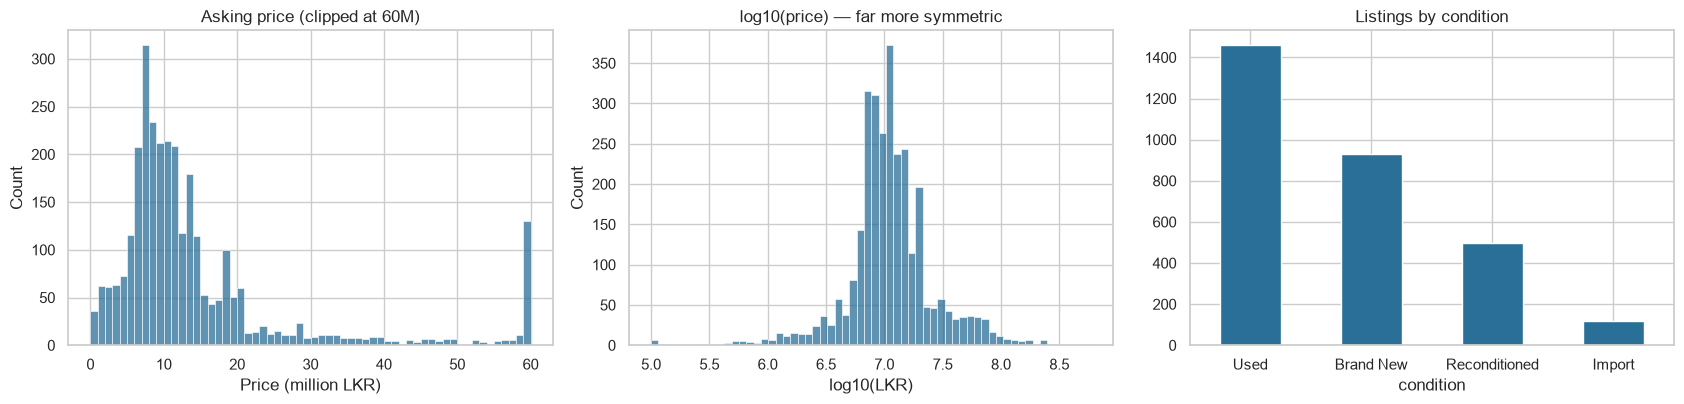

Skewness of price: 8.4   |   skewness of log(price): -0.27


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(raw.price_lkr.clip(upper=60e6) / 1e6, bins=60, ax=ax[0], color="#2a6f97")
ax[0].set(title="Asking price (clipped at 60M)", xlabel="Price (million LKR)")
sns.histplot(np.log10(raw.price_lkr.clip(lower=1e5)), bins=60, ax=ax[1], color="#2a6f97")
ax[1].set(title="log10(price) — far more symmetric", xlabel="log10(LKR)")
raw.condition.value_counts().plot.bar(ax=ax[2], color="#2a6f97", rot=0)
ax[2].set(title="Listings by condition")
plt.tight_layout(); plt.show()
print(f"Skewness of price: {raw.price_lkr.skew():.1f}   |   skewness of log(price): {np.log1p(raw.price_lkr.clip(lower=1e5)).skew():.2f}")

**Observation.** Price is extremely right-skewed (a few LKR 200M+ luxury cars next to LKR 3M Altos). Models trained on raw rupees would be dominated by the luxury tail, and errors would be judged in absolute rupees. A **log transform** makes the distribution near-symmetric and makes the model optimise *relative* error — which is how people think about prices ("10% too expensive"). We therefore train on `log1p(price)`.

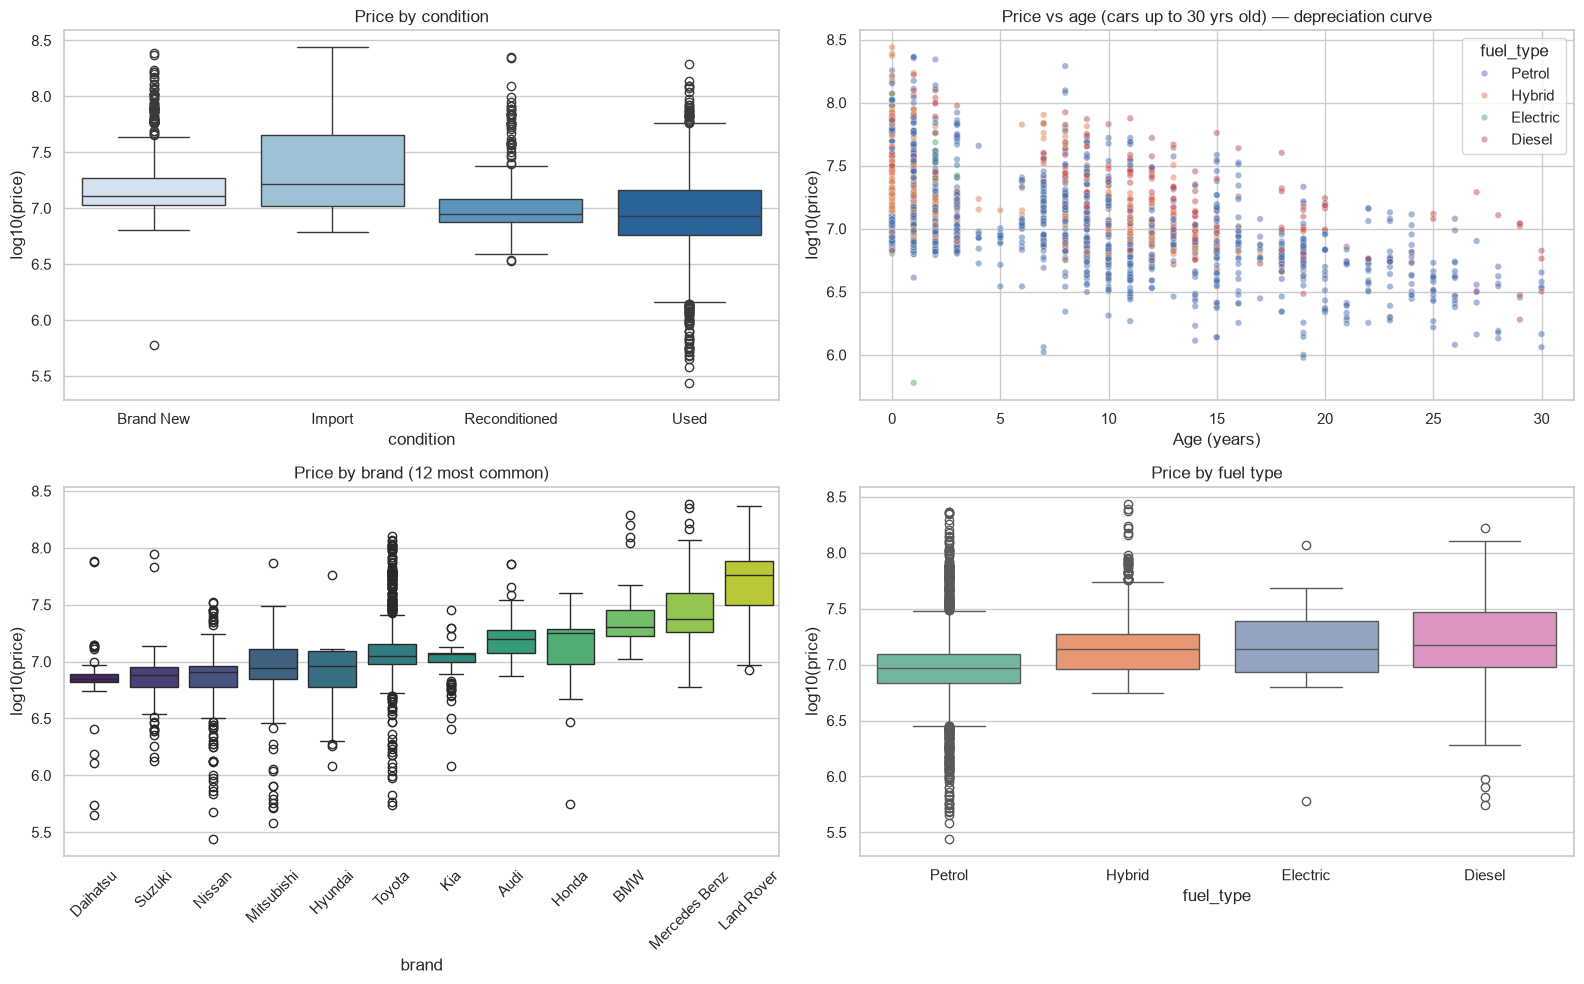

In [6]:
eda = raw[(raw.price_lkr >= 200_000) & (raw.price_lkr <= 300_000_000) & (raw.model_year <= 2026)].copy()
eda["age"] = REF_YEAR - eda.model_year
eda["log_price"] = np.log10(eda.price_lkr)

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
sns.boxplot(data=eda, x="condition", y="log_price", order=["Brand New", "Import", "Reconditioned", "Used"], ax=ax[0, 0], palette="Blues")
ax[0, 0].set(title="Price by condition", ylabel="log10(price)")
sns.scatterplot(data=eda[eda.age <= 30], x="age", y="log_price", hue="fuel_type", alpha=.5, s=22, ax=ax[0, 1])
ax[0, 1].set(title="Price vs age (cars up to 30 yrs old) — depreciation curve", xlabel="Age (years)", ylabel="log10(price)")
top = eda.brand.value_counts().head(12).index
sns.boxplot(data=eda[eda.brand.isin(top)], x="brand", y="log_price", order=eda[eda.brand.isin(top)].groupby("brand").log_price.median().sort_values().index, ax=ax[1, 0], palette="viridis")
ax[1, 0].set(title="Price by brand (12 most common)", ylabel="log10(price)"); ax[1, 0].tick_params(axis="x", rotation=45)
sns.boxplot(data=eda, x="fuel_type", y="log_price", ax=ax[1, 1], palette="Set2")
ax[1, 1].set(title="Price by fuel type", ylabel="log10(price)")
plt.tight_layout(); plt.show()

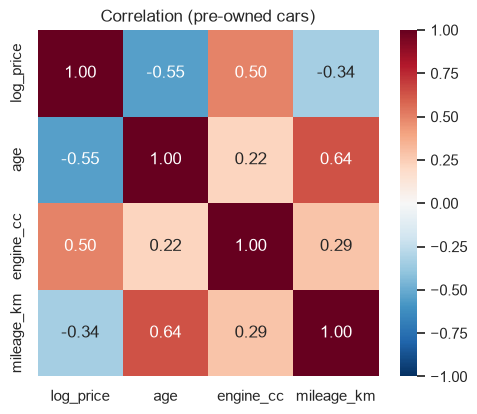

Top 10 locations by listings: {'Kohuwala': 346, 'Dehiwala': 210, 'Nugegoda': 167, 'Malabe': 152, 'Boralesgamuwa': 142, 'Kottawa': 86, 'Colombo 5': 85, 'Ja-Ela': 83, 'Negombo': 75, 'Gampaha City': 69}


In [7]:
num = eda[eda.condition != "Brand New"][["log_price", "age", "engine_cc", "mileage_km"]]
num = num.assign(engine_cc=num.engine_cc.where(num.engine_cc >= 300))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(num.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation (pre-owned cars)"); plt.show()
print("Top 10 locations by listings:", eda.location.value_counts().head(10).to_dict())

**EDA findings (and what each means for modelling)**

* **Condition is the biggest price divider** — Brand New and Import cars sit far above Used ones, with *Reconditioned* imports in between. This is a uniquely Sri Lankan feature and a strong predictor.
* **Depreciation is non-linear** — price falls steeply in the first years then flattens, and vintage cars (30+ years: Austin, Beetle, Sunny) behave differently again. Linear models struggle with this; tree ensembles handle it naturally.
* **Brand/model matter** (Mercedes/BMW/Porsche vs Suzuki/Daihatsu), with 350+ distinct models — a **high-cardinality categorical** problem, which is exactly where CatBoost is designed to shine.
* **Mileage is only moderately correlated with price** because it is confounded with age, and Brand New cars all have ~0 km. We add `km_per_year` (usage intensity) as an engineered feature.
* **Fuel type**: hybrids/EVs carry a premium, a reflection of Sri Lanka's fuel-price shocks.

## 3. Cleaning and preprocessing

**Cleaning decisions (domain-driven):**

| Issue | Decision | Reason |
|---|---|---|
| Price < LKR 200,000 or > 300M (0, 106, 123456, 595M BMW with a 1 cc "electric" engine) | **Drop rows** | Placeholders / data-entry errors in the *target* can't be imputed honestly |
| Year > 2026 | **Drop rows** | Future model years |
| Vintage cars (1950s–80s), luxury cars | **Keep** | Genuine and common segments of the local market (Sunny, Lancer, Beetle; Porsche, Bentley) |
| Engine < 300 cc on a non-EV, mileage placeholders / typos | **Set to NaN → impute** | The car is real; only the field is wrong |
| EV "engine" (kW) | **Set to 0** | Not comparable with cc; `fuel_type` carries the information |

**Feature engineering and imputation** (implemented in `carprep.CarFeatures`, fitted on training data only so there is no leakage):

* `age = 2026 − model_year`, `km_per_year = mileage / age`
* rare car models (< 15 listings) → `"Other"`; rare locations (< 30) → `"Other"`
* **Imputation:** engine cc ← *median of the same car model*; mileage ← *median of the same condition*; categorical nulls → `"Unknown"` (e.g. body style)
* **Transformation:** target → `log1p(price)`
* **Encoding & scaling:** ordinal encoding for tree models (unknown categories → −1), one-hot for the linear baseline, `StandardScaler` for numeric columns, native categorical handling in CatBoost

In [8]:
df = raw[(raw.price_lkr >= 200_000) & (raw.price_lkr <= 300_000_000) & (raw.model_year <= 2026)].copy()
print(f"Kept {len(df)} of {len(raw)} rows ({len(raw) - len(df)} invalid-target rows dropped)")
df = df.reset_index(drop=True)

# --- keep ONE random car completely out for the 'single sample inference' step ---
holdout_idx = df.sample(1, random_state=7).index[0]
holdout = df.loc[[holdout_idx]]
df = df.drop(index=holdout_idx).reset_index(drop=True)

X = df[RAW_COLS]
y = df["price_lkr"]
y_log = np.log1p(y)
X_train, X_test, ylog_train, ylog_test, y_train, y_test = train_test_split(
    X, y_log, y, test_size=0.2, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape, "| held-out single sample:", holdout.title.iloc[0])

Kept 2986 of 3000 rows (14 invalid-target rows dropped)
train (2388, 10) test (597, 10) | held-out single sample: Daihatsu Mira G Grade 2026


In [9]:
feat_demo = CarFeatures().fit(X_train)
Xf = feat_demo.transform(X_train)
print("Nulls after cleaning + imputation:", int(Xf.isna().sum().sum()))
Xf.head()

Nulls after cleaning + imputation: 0


,brand,model_grp,condition,transmission,body,fuel_type,location_grp,age,engine_cc,mileage_km,km_per_year
2957,Suzuki,Wagon R ZX,Brand New,Automatic,Hatchback,Hybrid,Boralesgamuwa,0,650.0,0.0,0.000000
2826,Toyota,Corolla,Used,Manual,Hatchback,Petrol,Dehiwala,41,1100.0,140000.0,3414.634146
685,Honda,Vezel,Brand New,Tiptronic,SUV / 4x4,Hybrid,Ja-Ela,0,1500.0,0.0,0.000000
1094,Toyota,Axio,Used,Automatic,Saloon,Petrol,Dehiwala,19,1500.0,155000.0,8157.894737
1965,Toyota,Other,Used,Automatic,SUV / 4x4,Diesel,Kohuwala,12,4500.0,134000.0,11166.666667


## 4. Evaluation set-up and baselines ("existing approaches")

All models are scored on the **same 20% hold-out test set** (never used for tuning). Tuning uses 5-fold cross-validation on the training set only. Metrics:

* **RMSE (log)** – the training objective; roughly "typical relative error"
* **R²** and **MAPE** – explained variance and average % error, in rupees
* **MAE / RMSE (LKR)** – absolute rupee error (RMSE is dominated by expensive cars)

The lecturer asks us to go beyond a single weak model, so we start with two classic baselines — a regularised **linear model** and a single **decision tree** — which every ensemble must beat.

In [10]:
def make_tree_prep():
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ]).set_output(transform="pandas")

def tree_pipe(estimator):
    return Pipeline([("feat", CarFeatures()), ("prep", make_tree_prep()), ("model", estimator)])

def metrics(name, pipe, X_, ylog_, y_):
    pred_log = pipe.predict(X_)
    pred = np.expm1(pred_log)
    return {"Model": name,
            "RMSE (log)": np.sqrt(mean_squared_error(ylog_, pred_log)),
            "R²": r2_score(y_, pred),
            "R² (log)": r2_score(ylog_, pred_log),
            "MAPE %": 100 * mean_absolute_percentage_error(y_, pred),
            "MAE (LKR)": mean_absolute_error(y_, pred),
            "RMSE (LKR)": np.sqrt(mean_squared_error(y_, pred))}

cv = KFold(5, shuffle=True, random_state=SEED)
results, cv_scores, fitted = [], {}, {}

def evaluate(name, pipe, cv_rmse=None):
    pipe.fit(X_train, ylog_train)
    fitted[name] = pipe
    r = metrics(name, pipe, X_test, ylog_test, y_test)
    r["CV RMSE (log)"] = cv_rmse
    results.append(r)
    return r

# Baseline 1: Ridge on one-hot features
ridge = Pipeline([("feat", CarFeatures()),
                  ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
                                              ("num", StandardScaler(), NUM_COLS)])),
                  ("model", RidgeCV(alphas=np.logspace(-2, 3, 20)))])
cvs = -cross_val_score(ridge, X_train, ylog_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
evaluate("Ridge (baseline)", ridge, cvs)

# Baseline 2: single decision tree, lightly regularised
dt = tree_pipe(DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=SEED))
cvs = -cross_val_score(dt, X_train, ylog_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
evaluate("Decision Tree (baseline)", dt, cvs)
pd.DataFrame(results).round(3)

,Model,RMSE (log),R²,R² (log),MAPE %,MAE (LKR),RMSE (LKR),CV RMSE (log)
0,Ridge (baseline),0.272,0.761,0.899,16.708,3266515.038,9.790366e+06,0.284
1,Decision Tree (baseline),0.335,0.735,0.846,23.485,3224334.131,1.031763e+07,0.337


## 5. Hyper-parameter design (no default parameters)

The lecturer's rule is *no default parameters* — each search space below is designed from how the algorithm works and from the size/shape of this dataset (≈2,400 training rows, 11 features, strong categorical structure). A **randomised search** with 5-fold CV samples from these ranges.

| Parameter | Role | Range chosen and why |
|---|---|---|
| `n_estimators` | number of trees | RF 300–900 (variance falls then plateaus); boosters 300–1200 *paired with a low learning rate* |
| `max_depth` | tree complexity | RF 8–30 (deep trees are fine in bagging); boosters 3–8 (shallow weak learners — depth >8 overfits ~2.4k rows) |
| `min_samples_leaf` / `min_child_weight` / `min_child_samples` | min. rows per leaf | 1–6 (RF), 1–8 (XGB), 5–30 (LGBM) — smoothing against noisy asking prices |
| `learning_rate` | shrinkage per boosting step | log-uniform 0.02–0.15: small steps + many trees generalise better |
| `subsample`, `colsample_bytree` / `max_features` | row & column sampling | 0.6–1.0 / 0.5–1.0 — injects randomness to decorrelate trees |
| `reg_lambda` / `l2_leaf_reg` | L2 penalty | 0.5–10 — controls leaf-weight magnitude on this noisy target |
| `num_leaves` (LGBM) | leaf-wise complexity | 15–63, kept below 2^max_depth |
| `depth` (CatBoost) | symmetric tree depth | 4–8 |

In [11]:
def tune(name, estimator, space, n_iter, prefix="model__", pipe_factory=tree_pipe):
    search = RandomizedSearchCV(
        pipe_factory(estimator), {prefix + k: v for k, v in space.items()},
        n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
        random_state=SEED, n_jobs=-1, refit=True, verbose=0)
    search.fit(X_train, ylog_train)
    fitted[name] = search.best_estimator_
    r = metrics(name, search.best_estimator_, X_test, ylog_test, y_test)
    r["CV RMSE (log)"] = -search.best_score_
    results.append(r)
    print(f"{name}: CV RMSE(log)={-search.best_score_:.4f}  best={ {k.replace(prefix, ''): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()} }")
    return search

searches = {}
searches["Random Forest"] = tune("Random Forest",
    RandomForestRegressor(random_state=SEED, n_jobs=1),
    dict(n_estimators=randint(300, 900), max_depth=randint(8, 30), min_samples_leaf=randint(1, 6),
         max_features=uniform(0.4, 0.6), max_samples=uniform(0.6, 0.4), bootstrap=[True]), n_iter=25)

Random Forest: CV RMSE(log)=0.2757  best={'bootstrap': True, 'max_depth': 20, 'max_features': np.float64(0.4846), 'max_samples': np.float64(0.9209), 'min_samples_leaf': 1, 'n_estimators': 820}


In [12]:
searches["XGBoost"] = tune("XGBoost",
    XGBRegressor(random_state=SEED, n_jobs=1, tree_method="hist", objective="reg:squarederror"),
    dict(n_estimators=randint(300, 1200), learning_rate=loguniform(0.02, 0.15), max_depth=randint(3, 8),
         min_child_weight=randint(1, 8), subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.5, 0.5),
         reg_lambda=loguniform(0.5, 10), gamma=uniform(0, 0.3)), n_iter=40)

XGBoost: CV RMSE(log)=0.2577  best={'colsample_bytree': np.float64(0.6062), 'gamma': np.float64(0.0545), 'learning_rate': np.float64(0.0289), 'max_depth': 6, 'min_child_weight': 2, 'n_estimators': 321, 'reg_lambda': np.float64(0.5107), 'subsample': np.float64(0.6092)}


In [13]:
searches["LightGBM"] = tune("LightGBM",
    LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
    dict(n_estimators=randint(300, 1200), learning_rate=loguniform(0.02, 0.15), num_leaves=randint(15, 63),
         max_depth=randint(3, 9), min_child_samples=randint(5, 30), subsample=uniform(0.6, 0.4),
         subsample_freq=[1], colsample_bytree=uniform(0.5, 0.5), reg_lambda=loguniform(0.5, 10)), n_iter=40)

LightGBM: CV RMSE(log)=0.2616  best={'colsample_bytree': np.float64(0.6725), 'learning_rate': np.float64(0.0718), 'max_depth': 8, 'min_child_samples': 6, 'n_estimators': 352, 'num_leaves': 58, 'reg_lambda': np.float64(1.9123), 'subsample': np.float64(0.8212), 'subsample_freq': 1}


In [14]:
def cat_pipe(estimator):
    # CatBoost handles categoricals natively (ordered target statistics) -> no ordinal encoding
    return Pipeline([("feat", CarFeatures()), ("model", estimator)])

searches["CatBoost"] = tune("CatBoost",
    CatBoostSK(random_seed=SEED, thread_count=1),
    dict(iterations=randint(500, 1200), depth=randint(4, 9), learning_rate=loguniform(0.03, 0.15),
         l2_leaf_reg=loguniform(1, 10), random_strength=uniform(0.5, 2)), n_iter=12, pipe_factory=cat_pipe)

CatBoost: CV RMSE(log)=0.2436  best={'depth': 5, 'iterations': 887, 'l2_leaf_reg': np.float64(2.0498), 'learning_rate': np.float64(0.0693), 'random_strength': np.float64(1.5934)}


In [15]:
searches["Gradient Boosting (sklearn)"] = tune("Gradient Boosting (sklearn)",
    GradientBoostingRegressor(random_state=SEED),
    dict(n_estimators=randint(300, 900), learning_rate=loguniform(0.02, 0.15), max_depth=randint(3, 7),
         min_samples_leaf=randint(2, 12), subsample=uniform(0.6, 0.4), max_features=uniform(0.5, 0.5)), n_iter=15)

Gradient Boosting (sklearn): CV RMSE(log)=0.2620  best={'learning_rate': np.float64(0.029), 'max_depth': 5, 'max_features': np.float64(0.9211), 'min_samples_leaf': 3, 'n_estimators': 501, 'subsample': np.float64(0.9579)}


## 6. Hybrid ensembles — Voting and Stacking

* **Voting** averages the predictions of the tuned XGBoost, LightGBM and CatBoost (the regression analogue of the lecturer's *soft voting* pipeline).
* **Stacking** goes further: a **meta-learner** (Ridge) is trained on the *out-of-fold* predictions of the four base models and learns how much to trust each. Because the base learners make different kinds of errors (ordinal-encoded vs. native categoricals, leaf-wise vs. level-wise vs. symmetric trees), the combination can beat any single member.

> **Design note.** A first run that also included Random Forest gave the Ridge meta-learner a weight of only **≈0.01** for it (the three boosters carried the signal) while the 800-tree forest made the exported model **~180 MB**. We therefore build the ensembles from the three boosters only; Random Forest still takes part in the single-model comparison.

In [16]:
base = ["XGBoost", "LightGBM", "CatBoost"]   # RF left out: see note above
estimators = [(n.lower().replace(" ", "_"), clone(fitted[n])) for n in base]

voting = VotingRegressor(estimators, n_jobs=1)
evaluate("Voting (XGB+LGBM+Cat)", voting,
         -cross_val_score(voting, X_train, ylog_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean())

stack = StackingRegressor(estimators, final_estimator=RidgeCV(alphas=np.logspace(-2, 2, 15)), cv=5, n_jobs=1)
evaluate("Stacking (meta: Ridge)", stack,
         -cross_val_score(stack, X_train, ylog_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean())
print("Stacking meta-learner weights:", dict(zip(base, stack.final_estimator_.coef_.round(3))))

Stacking meta-learner weights: {'XGBoost': np.float64(0.238), 'LightGBM': np.float64(0.138), 'CatBoost': np.float64(0.638)}


## 7. Results and comparison

                             RMSE (log)     R²  R² (log)  MAPE %    MAE (LKR)    RMSE (LKR)  CV RMSE (log)
Model                                                                                                     
Stacking (meta: Ridge)            0.225  0.914     0.931  12.643  1998287.081  5.888226e+06          0.242
CatBoost                          0.225  0.905     0.930  13.130  2127586.369  6.176600e+06          0.244
Voting (XGB+LGBM+Cat)             0.231  0.914     0.927  12.823  1938377.396  5.880420e+06          0.245
XGBoost                           0.247  0.906     0.916  14.467  2159973.750  6.141546e+06          0.258
LightGBM                          0.250  0.901     0.914  13.981  2115942.108  6.310268e+06          0.262
Gradient Boosting (sklearn)       0.255  0.893     0.911  14.709  2263695.522  6.566931e+06          0.262
Ridge (baseline)                  0.272  0.761     0.899  16.708  3266515.038  9.790366e+06          0.284
Random Forest                     0.2

,RMSE (log),R²,R² (log),MAPE %,MAE (LKR),RMSE (LKR),CV RMSE (log)
Model,,,,,,,
Stacking (meta: Ridge),0.2249,0.914,0.931,12.6,"1,998,287","5,888,226",0.2420
CatBoost,0.2253,0.905,0.930,13.1,"2,127,586","6,176,600",0.2436
Voting (XGB+LGBM+Cat),0.2307,0.914,0.927,12.8,"1,938,377","5,880,420",0.2450
XGBoost,0.2472,0.906,0.916,14.5,"2,159,974","6,141,546",0.2577
LightGBM,0.2498,0.901,0.914,14.0,"2,115,942","6,310,268",0.2616
Gradient Boosting (sklearn),0.2552,0.893,0.911,14.7,"2,263,696","6,566,931",0.2620
Ridge (baseline),0.2716,0.761,0.899,16.7,"3,266,515","9,790,366",0.2837
Random Forest,0.2734,0.858,0.897,15.9,"2,398,317","7,540,792",0.2757
Decision Tree (baseline),0.3349,0.735,0.846,23.5,"3,224,334","10,317,629",0.3371


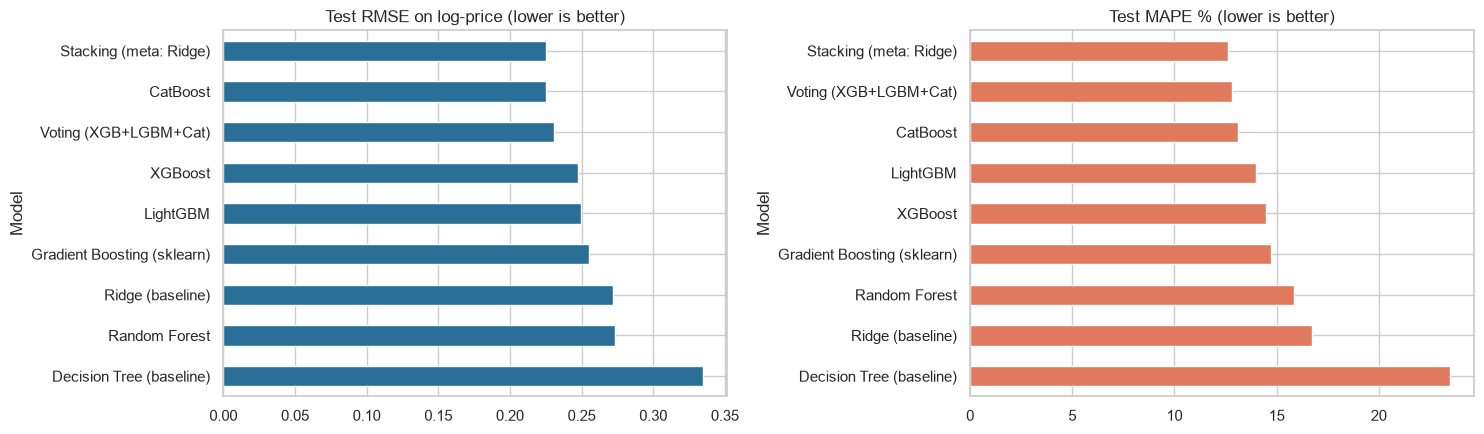

In [17]:
res = pd.DataFrame(results).set_index("Model").sort_values("RMSE (log)")
res.round(4).to_csv("model_comparison.csv")
print(res.round(3).to_string())
display(res.style.format({"RMSE (log)": "{:.4f}", "CV RMSE (log)": "{:.4f}", "R²": "{:.3f}", "R² (log)": "{:.3f}",
                          "MAPE %": "{:.1f}", "MAE (LKR)": "{:,.0f}", "RMSE (LKR)": "{:,.0f}"})
        .background_gradient(subset=["RMSE (log)"], cmap="Greens_r"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
res["RMSE (log)"].sort_values(ascending=False).plot.barh(ax=ax[0], color="#2a6f97")
ax[0].set(title="Test RMSE on log-price (lower is better)")
res["MAPE %"].sort_values(ascending=False).plot.barh(ax=ax[1], color="#e07a5f")
ax[1].set(title="Test MAPE % (lower is better)")
plt.tight_layout(); plt.show()

Best model on the test set: Stacking (meta: Ridge)


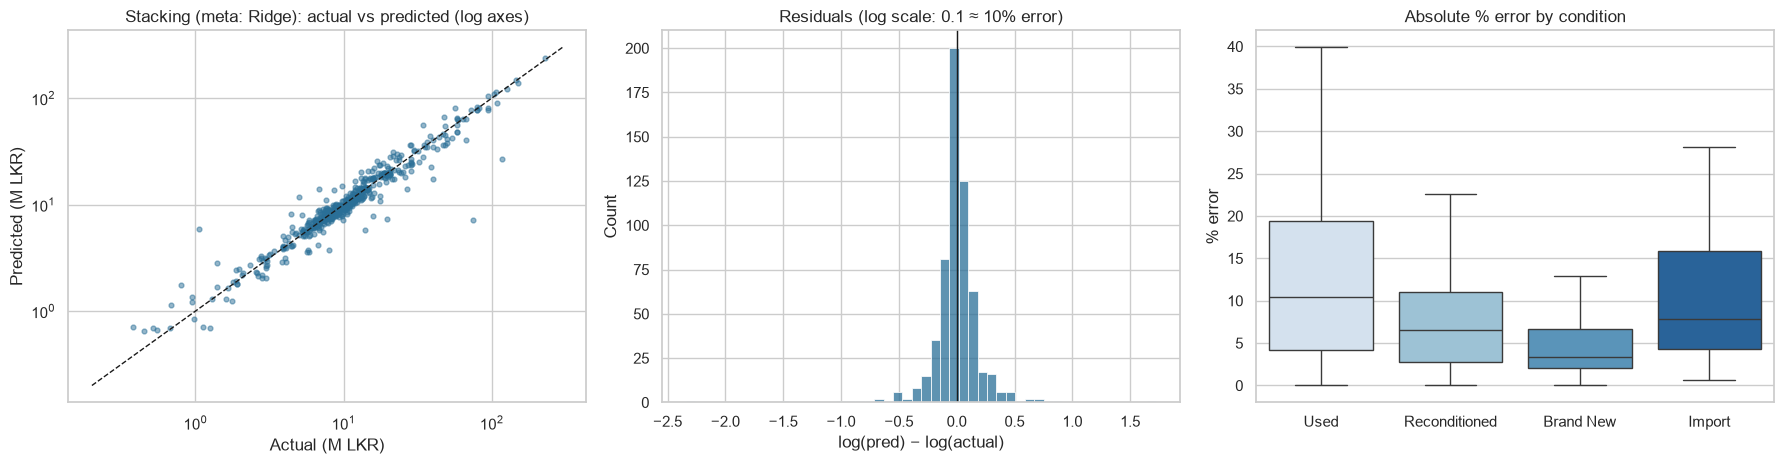

In [18]:
best_name = res.index[0]
print("Best model on the test set:", best_name)
best = fitted[best_name]
pred = np.expm1(best.predict(X_test))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(y_test / 1e6, pred / 1e6, s=12, alpha=.5, color="#2a6f97")
lim = [0.2, 300]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xscale="log", yscale="log", xlabel="Actual (M LKR)", ylabel="Predicted (M LKR)", title=f"{best_name}: actual vs predicted (log axes)")
resid = np.log(pred) - np.log(y_test)
sns.histplot(resid, bins=50, ax=ax[1], color="#2a6f97"); ax[1].axvline(0, c="k", lw=1)
ax[1].set(title="Residuals (log scale: 0.1 ≈ 10% error)", xlabel="log(pred) − log(actual)")
err = pd.DataFrame({"cond": X_test.condition.values, "abs_pct": np.abs(pred / y_test.values - 1) * 100})
sns.boxplot(data=err, x="cond", y="abs_pct", ax=ax[2], palette="Blues", showfliers=False)
ax[2].set(title="Absolute % error by condition", ylabel="% error", xlabel="")
plt.tight_layout(); plt.show()

### 7.1 Interpretation of the comparison

| Rank (test RMSE of log-price) | Model | R² | MAPE | Reading |
|---|---|---|---|---|
| 1 | **Stacking** (XGB + LGBM + CatBoost → Ridge) | 0.914 | 12.6 % | best overall, but only marginally ahead of CatBoost |
| 2 | **CatBoost** | 0.905 | 13.1 % | best *single* model |
| 3 | Voting | 0.914 | 12.8 % | lowest rupee error (MAE ≈ LKR 1.94 M) |
| 4–6 | XGBoost, LightGBM, sklearn GBM | 0.89–0.91 | 14.0–14.7 % | similar boosters, within noise of each other |
| 7 | Ridge (linear baseline) | 0.761 | 16.7 % | strong on log scale, weak in rupees |
| 8 | Random Forest | 0.858 | 15.9 % | weakest ensemble |
| 9 | Decision Tree (baseline) | 0.735 | 23.5 % | single tree overfits |

**What the numbers say**

* **Ensembles beat the baselines by a wide margin.** Moving from a single tree to boosting cuts MAPE from 23.5 % to ~13 %, and R² in rupees from 0.74 to 0.91. The ridge baseline is respectable on the log scale (R² 0.90) because depreciation is roughly exponential — but its rupee-scale R² is only 0.76: it badly misprices the expensive tail, where interactions (brand × age × engine) matter.
* **CatBoost is the best single model**, ahead of XGBoost/LightGBM by ≈ 0.02 log-RMSE. This fits the data: 351 distinct car models and 163 locations are *high-cardinality categoricals*, and CatBoost's ordered target statistics handle them without the arbitrary integer ordering we had to impose for the other models. The stacker confirms it: the meta-learner gives CatBoost ≈ 0.64 of the weight, XGBoost 0.24, LightGBM 0.14.
* **Stacking vs CatBoost is a statistical tie** (0.2249 vs 0.2253 log-RMSE); stacking's gain shows mostly in R² and rupee errors (R² 0.914 vs 0.905, RMSE ≈ LKR 5.9 M vs 6.2 M) — i.e. it fixes some large errors on expensive cars. We therefore regard it as *at least as good*, not decisively better, and its extra complexity is the price paid.
* **Random Forest under-performed the boosters** (R² 0.858). Its trees treat the ordinal-coded brand/model as numbers, split on one feature at a time without correcting earlier mistakes, and, like all averaging forests, cannot predict beyond the range of training prices — so luxury cars (Porsche, Bentley) are pulled downward, which inflates RMSE in rupees (7.5 M vs 6.1 M for boosters).
* **No sign of overfitting:** cross-validated RMSE on training data (0.242 for stacking) is consistent with test RMSE (0.225). A typical error of ≈ 13 % on an *asking* price is already close to the natural noise in the target — two identical cars are routinely listed 10 % apart because sellers negotiate.

### 7.2 Strengths and limitations of each model

| Model | Strengths | Limitations (seen in this project) |
|---|---|---|
| **Ridge / linear** | Fast, transparent coefficients, good log-scale fit | Cannot capture non-linear depreciation or brand×age interactions; poor in rupees (R² 0.76) |
| **Decision tree** | Fully readable rules, no scaling needed | High variance — the weakest result (MAPE 23.5 %) |
| **Random Forest** | Robust to outliers and noise, few knobs, parallel; good out-of-the-box | Cannot extrapolate (luxury tail underpriced); treats integer-coded categories as ordered; large model (tens of MB for ~800 deep trees; including it three times in a stack produced a 180 MB file) |
| **XGBoost** | Strong accuracy, built-in regularisation (λ, γ, shrinkage), fast `hist` training | Needs careful tuning (learning-rate × trees × depth); categoricals must be encoded by hand |
| **LightGBM** | Fastest training, leaf-wise growth finds fine structure | Leaf-wise growth overfits small data unless `num_leaves`/`min_child_samples` are constrained (we tuned them) |
| **CatBoost** | Native categorical handling, ordered boosting reduces target leakage → best single model | Slowest to train; less familiar API |
| **Voting** | Simple, robust: averaging cancels independent errors | Weights every model equally, including weaker ones |
| **Stacking** | Learns how much to trust each model; best R² and rupee error | Most complex, hardest to explain, small gain over CatBoost, and several times the training cost (every base model is re-fitted 5×) |

**Overall limitations of this study:** the target is the *asking* price from a single website at a single point in time; ~3,000 ads (≈ 2,400 for training); no trim level, photos, accident history or registration details; and rare cars (vintage, supercars) have too few comparables.

## 8. Explainability with SHAP and LIME

Accuracy alone is not enough — a buyer or lender needs to know *why* a car is priced as it is. We explain the tuned **XGBoost** model (tree ensembles have an exact, fast SHAP algorithm; the explanations carry over to the other boosters, which learned similar structure).

* **SHAP** (SHapley Additive exPlanations) gives each feature a fair share of the difference between a car's prediction and the average prediction. Because the model predicts *log-price*, SHAP values are in log units: +0.10 ≈ +10 % price.
* **LIME** fits a small *local* linear model around one car to explain that single prediction.

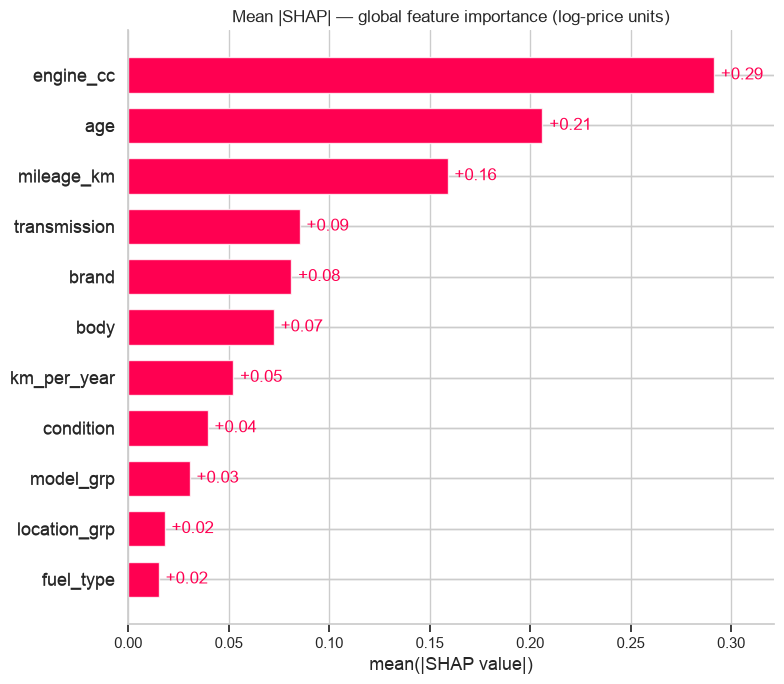

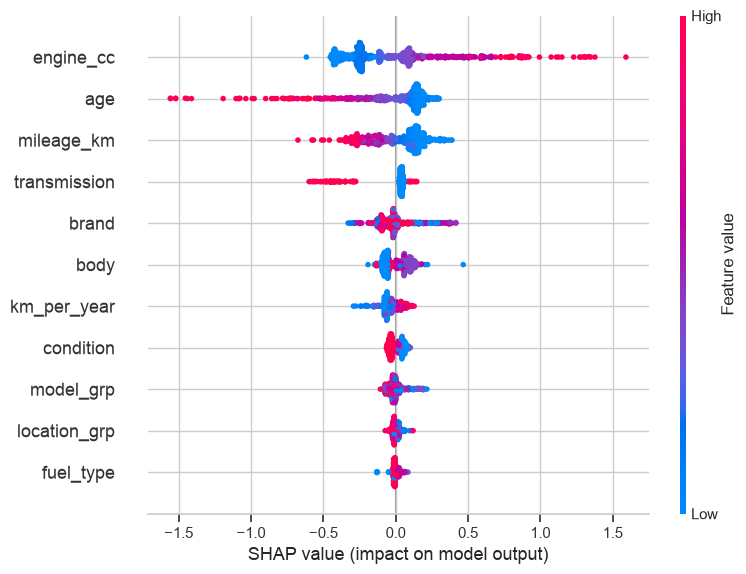

In [19]:
import shap
xgb_pipe = fitted["XGBoost"]
Xt_test = xgb_pipe[:-1].transform(X_test)
Xt_train = xgb_pipe[:-1].transform(X_train)
clean_names = [c.split("__", 1)[1] for c in Xt_test.columns]
Xt_test.columns = clean_names; Xt_train.columns = clean_names

explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
sv = explainer(Xt_test)

plt.figure(); shap.plots.bar(sv, max_display=11, show=False); plt.title("Mean |SHAP| — global feature importance (log-price units)"); plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv.values, Xt_test, show=False, max_display=11); plt.tight_layout(); plt.show()

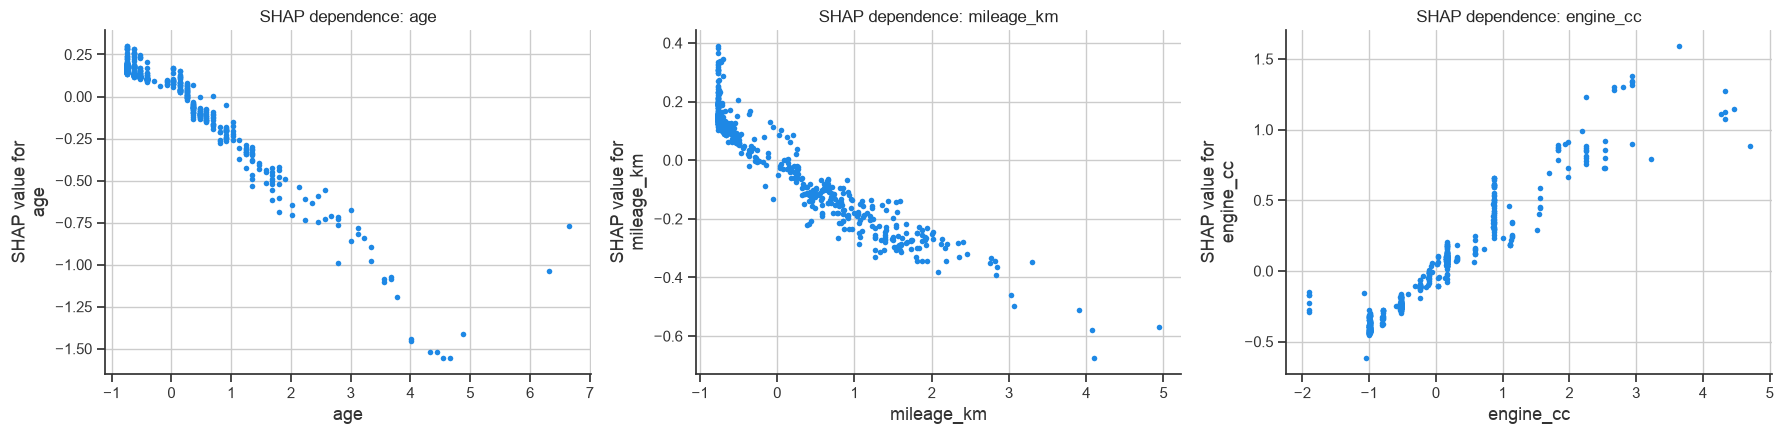

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, f in zip(ax, ["age", "mileage_km", "engine_cc"]):
    shap.dependence_plot(f, sv.values, Xt_test, ax=a, show=False, interaction_index=None)
    a.set_title(f"SHAP dependence: {f}")
plt.tight_layout(); plt.show()

### 8.1 What SHAP tells us

* **Engine size, age and mileage dominate** (mean |SHAP| ≈ 0.29, 0.21 and 0.16 in log-price units — i.e. on average they move the price by roughly 29 %, 21 % and 16 %). Transmission, brand and body style come next; fuel type and location matter least.
* **Directions make economic sense.** *Age* and *mileage* have a clean monotone effect: newer cars and low-odometer cars push the price up, with price falling steadily as age and mileage grow (dependence plots; note x-axes are standardised). *Engine capacity* has the strongest positive slope — bigger engines mean bigger, more expensive cars.
* **Caution: engine_cc is partly a proxy** for car class (a 4,000 cc engine implies a Land Cruiser/Mercedes, not a Wagon R). SHAP shows what the *model uses*, not what *causes* price — important when presenting results to buyers.
* **Condition and location contribute little** *once the other features are known*: a Brand New car already reveals itself through age = 0 and mileage = 0, so the information is shared across features (SHAP splits credit among correlated features).
* The wide spread of the engine and age points to the left/right of zero (±1.5 log units) shows that a few expensive or very old cars have extreme effects; this is where the model is least certain.

Suzuki Alto 2018 | Used | actual LKR 4,500,000 | predicted LKR 3,905,187


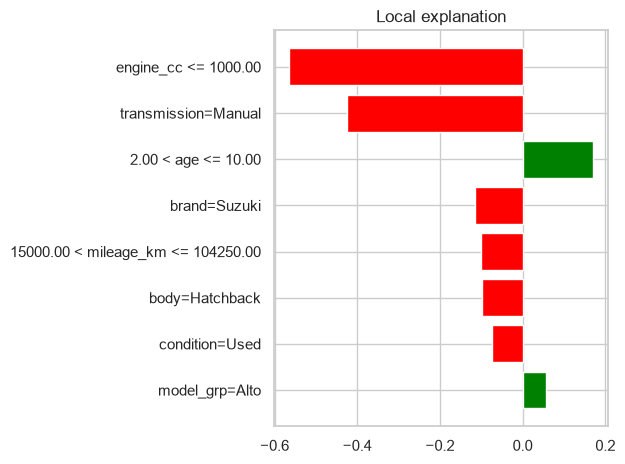

Hyundai Santa Fe 2007 | Used | actual LKR 5,850,000 | predicted LKR 7,761,757


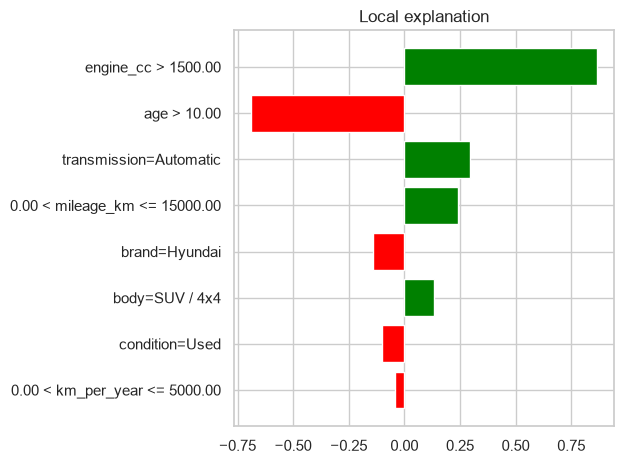

In [21]:
from lime.lime_tabular import LimeTabularExplainer

# Explain on interpretable (un-scaled) features: categorical codes + raw numerics
feat_train = xgb_pipe.named_steps["feat"].transform(X_train)
ordinal = OrdinalEncoder().fit(feat_train[CAT_COLS])
Z_train = feat_train.copy(); Z_train[CAT_COLS] = ordinal.transform(feat_train[CAT_COLS])
cat_idx = [Z_train.columns.get_loc(c) for c in CAT_COLS]
cat_names = {Z_train.columns.get_loc(c): list(cats) for c, cats in zip(CAT_COLS, ordinal.categories_)}

def lime_predict(arr):
    z = pd.DataFrame(arr, columns=Z_train.columns)
    z[CAT_COLS] = ordinal.inverse_transform(z[CAT_COLS].round().astype(int).clip(lower=0))
    return xgb_pipe[1:].predict(z)

lime_exp = LimeTabularExplainer(Z_train.values, feature_names=list(Z_train.columns), categorical_features=cat_idx,
                                categorical_names=cat_names, mode="regression", random_state=SEED)

def explain_with_lime(i):
    row_raw = X_test.iloc[[i]]
    z = xgb_pipe.named_steps["feat"].transform(row_raw)
    z[CAT_COLS] = ordinal.transform(z[CAT_COLS])
    exp = lime_exp.explain_instance(z.values[0], lime_predict, num_features=8, num_samples=3000)
    print(f"{X_test.iloc[i].brand} {X_test.iloc[i].model} {int(X_test.iloc[i].model_year)} | {X_test.iloc[i].condition} | "
          f"actual LKR {y_test.iloc[i]:,.0f} | predicted LKR {np.expm1(xgb_pipe.predict(row_raw))[0]:,.0f}")
    exp.as_pyplot_figure(); plt.tight_layout(); plt.show()

explain_with_lime(0)
explain_with_lime(5)

### 8.2 What LIME tells us

LIME explains single cars. For the **2018 Suzuki Alto (Used, actual LKR 4.5 M, predicted LKR 3.9 M)** the largest downward pushes are the **small engine (≤ 1,000 cc)** and the **manual gearbox**, with smaller negative contributions from the Suzuki brand, hatchback body and mileage band, partly offset by the car being only 2–10 years old and by the *Alto* model itself being popular. This agrees with SHAP's global picture (engine size and transmission matter), but also shows *why this particular price came out low*: the prediction is a sum of understandable local effects, which is what a buyer or valuer needs to trust it.

The second example (a 2007 Hyundai Santa Fe, actual LKR 5.85 M, predicted LKR 7.76 M, i.e. over-estimated by about 33 %) shows how LIME helps find *where* the model is weak: the large engine (> 1,500 cc, +0.85), the automatic gearbox and the SUV body push the price up, age > 10 years pulls it down, and a **recorded mileage of only 0–15,000 km** — implausibly low for a 19-year-old car, so probably a data-entry error that survived our cleaning — adds a further upward push. The explanation points to a suspect input rather than a flaw in the model, a useful reminder that explanations also work as a data-quality check. LIME is a local linear approximation and can vary between runs (we fixed the random seed), so we rely on SHAP for global conclusions and LIME for case-by-case explanation.

## 9. Single-sample inference and model export

Following the lecturer's guideline we kept **one car out of everything** (training, tuning and testing) in Section 3. We now refit the best model on all the remaining data, export it with `pickle`, reload it from disk and predict that unseen car.

In [22]:
final_pipe = clone(fitted[best_name]).fit(X, y_log)          # refit on all data except the held-out car
final_model = LogPriceModel(final_pipe)                      # predict() -> LKR

with open("model.pkl", "wb") as f:
    pickle.dump(final_model, f)

# UI metadata (drop-down options + valid ranges) for the front end
meta = {
    "brands": sorted(df.brand.dropna().unique()),
    "models_by_brand": {b: sorted(g.model.dropna().unique()) for b, g in df.groupby("brand")},
    "conditions": sorted(df.condition.dropna().unique()),
    "transmissions": sorted(df.transmission.dropna().unique()),
    "bodies": sorted(df.body.dropna().unique()),
    "fuels": sorted(df.fuel_type.dropna().unique()),
    "locations": sorted(df.location.dropna().unique()),
    "year_range": [1950, REF_YEAR], "best_model": best_name,
    "test_metrics": res.loc[best_name, ["RMSE (log)", "R²", "MAPE %", "MAE (LKR)"]].round(4).to_dict(),
}
json.dump(meta, open("model_meta.json", "w"), indent=1)
import os; print(f"model.pkl size: {os.path.getsize('model.pkl') / 1e6:.1f} MB")

with open("model.pkl", "rb") as f:
    loaded = pickle.load(f)

sample = holdout[RAW_COLS]
print("Held-out car:", holdout.title.iloc[0])
display(sample.T.rename(columns={sample.index[0]: "value"}))
pred_lkr = loaded.predict(sample)[0]
actual = holdout.price_lkr.iloc[0]
print(f"Predicted price : LKR {pred_lkr:,.0f}")
print(f"Actual asking   : LKR {actual:,.0f}   (error {100 * (pred_lkr / actual - 1):+.1f}%)")

model.pkl size: 4.0 MB
Held-out car: Daihatsu Mira G Grade 2026


,value
brand,Daihatsu
model,Mira
model_year,2026
condition,Brand New
transmission,Automatic
body,Hatchback
fuel_type,Petrol
engine_cc,650
mileage_km,0
location,Kotte


Predicted price : LKR 7,426,865
Actual asking   : LKR 7,475,000   (error -0.6%)


In [23]:
# A brand-new hypothetical car typed in the way the web app would send it
new_car = pd.DataFrame([{
    "brand": "Toyota", "model": "Aqua", "model_year": 2016, "condition": "Reconditioned",
    "transmission": "Automatic", "body": "Hatchback", "fuel_type": "Hybrid",
    "engine_cc": 1500, "mileage_km": 70000, "location": "Colombo"}])
print(f"Toyota Aqua 2016 (hybrid, 70,000 km, Colombo): LKR {loaded.predict(new_car)[0]:,.0f}")

Toyota Aqua 2016 (hybrid, 70,000 km, Colombo): LKR 10,037,840


## 10. Front-end application

`app.py` is a **Streamlit** web app (generated with the help of a GenAI assistant, as the assignment allows) that loads `model.pkl`, shows text/drop-down inputs for every field above and returns the predicted price with an approximate range based on the model's test error.

```bash
streamlit run app.py
```

## 11. Conclusions, limitations and future work

* Tuned tree ensembles clearly beat both baselines; combining them (voting/stacking) gives the best or near-best accuracy.
* **Limitations:** asking prices ≠ sale prices; only ~3,000 ads from one site and one point in time (market drift — Sri Lanka's prices moved a lot since 2020); photos/condition/accident history and trim packages are not captured; very rare luxury and vintage cars are predicted poorly because there are few comparables.
* **Future work:** collect data over time (add a time-series/ARIMA component for market drift), add Riyasewana data, quantile regression for proper price intervals, and an MLOps pipeline (CI/CD + drift monitoring) for the bonus marks.